# 02 - Download and preprocessing: from SOAR files to the fitting-ready file

**This notebook ships pre-executed.** Running it needs the raw EAS files (830 MB per six
hours), the SOAR RPW potential files (170 MB per day) and a network connection for MAG,
PAS and RPW density (CDAWeb). Read the outputs; run it when you preprocess your own
interval. The other notebooks start from the bundled example and need none of this.

**Runtime when executed:** about 3 minutes per six-hour segment, downloads aside.

## What the preprocessing does

`src/preprocess_data_for_fit_hdf5.py` writes six-hour
`VDF_eas_forFitting_<start>_<end>_1min.h5` files:

1. read the **L2 PSD** of both heads and the **L1 counts** (PSD / counts is the
   one-count level of notebook 01);
2. mask L1 telemetry blocks at the counter **saturation value** 65 535 (set to NaN;
   census in `n_saturated_pixels`);
3. fetch **MAG**, **PAS** and the **RPW electron density** through `cdasws`;
4. subtract the **spacecraft potential** from the energies: automatic before 2023, from
   a table afterwards (section 2);
5. rotate every pixel into the field-aligned frame: pitch angle, $v_\parallel$,
   $v_\perp$;
6. merge the heads into one 64 x 1024 grid, build the 18-bin PAD, resample to 1 minute,
   write compressed.

The EAS geometric factors and efficiencies ship in `examples/example_data/`.

In [1]:
import os
import sys
from pathlib import Path

# Single-threaded linear algebra, set before numpy is imported: the fits are
# many small least-squares problems, and this makes the numbers in this
# notebook identical to those of the batch runner (which spawns 1-thread workers).
for name in ('OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS'):
    os.environ.setdefault(name, '1')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Repository root = the first parent directory that contains src/evdf_poisson
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'evdf_poisson').is_dir())
sys.path.insert(0, str(REPO_ROOT / 'src'))

CALIBRATION_DIR = REPO_ROOT / 'examples' / 'example_data'          # EAS geometric factors, head geometry, scpot table
EXAMPLE_DIR = CALIBRATION_DIR / 'poisson_2023-04-04'                # the 30-epoch example subset
EXAMPLE_FILE = EXAMPLE_DIR / 'VDF_eas_forFitting_20230404005008_20230404011908_1min.h5'
RESULTS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_run_poisson'       # reference fit of the subset
DAYS_DIR = REPO_ROOT / 'results' / 'fitting' / 'example_days_2023-04-04_05'   # reference fit of the two full days
GEOMETRY_FILE = CALIBRATION_DIR / 'eas_head_geometry.npz'
print('repository:', REPO_ROOT)

repository: /disk/plasma/xw2/SO-EAS-eVDF_Fitting


## 1. The EAS files from SOAR

`download_L2_PSD_from_SOAR.py` queries the Solar Orbiter Archive through `sunpy-soar`,
day by day, for the L2 `swa-eas{1,2}-nm3d-psd` and L1 `swa-eas{1,2}-nm3d` products and
keeps the newest version of every file. Files go to `data/vdfs/` and `data/L1_Count/`
(both ignored by git).

Do not mix V01 and V03 files in one run: their energy tables have different dimensions.

The cell lists what is on disk for the first six hours of 2023-04-04. Set
`DOWNLOAD_IF_MISSING = True` to fetch the four files (about 830 MB).

In [2]:
from download_L2_PSD_from_SOAR import (discoverLocalL2Psd, discoverLocalL1Count,
                                       downloadSoL2PsdNm3d, downloadSoL1CountNm3d)

RAW_DIR = REPO_ROOT / 'data'
SEGMENT = ['2023-04-04 00:00:00', '2023-04-04 06:00:00']
DOWNLOAD_IF_MISSING = False

eas1PsdFiles, eas2PsdFiles = discoverLocalL2Psd(SEGMENT, downloadDir=str(RAW_DIR / 'vdfs'))
eas1CountFiles, eas2CountFiles = discoverLocalL1Count(SEGMENT, downloadDir=str(RAW_DIR / 'L1_Count'))
if DOWNLOAD_IF_MISSING and not (eas1PsdFiles and eas2PsdFiles):
    eas1PsdFiles, eas2PsdFiles = downloadSoL2PsdNm3d(SEGMENT, downloadDir=str(RAW_DIR / 'vdfs'))
if DOWNLOAD_IF_MISSING and not (eas1CountFiles and eas2CountFiles):
    eas1CountFiles, eas2CountFiles = downloadSoL1CountNm3d(SEGMENT, downloadDir=str(RAW_DIR / 'L1_Count'))

rawFiles = [*eas1PsdFiles, *eas2PsdFiles, *eas1CountFiles, *eas2CountFiles]
hasRawFiles = len(rawFiles) == 4
for path in rawFiles:
    print(f'{Path(path).name:70s} {Path(path).stat().st_size / 1e6:6.0f} MB')
if not hasRawFiles:
    print('raw files missing: the preprocessing cells below are skipped (set DOWNLOAD_IF_MISSING = True to fetch them)')

Found 1 EAS1 and 1 EAS2 local L2 PSD files overlapping 2023-04-04 00:00:00 to 2023-04-04 06:00:00 in /disk/plasma/xw2/SO-EAS-eVDF_Fitting/data/vdfs
Found 1 EAS1 and 1 EAS2 local L1 count files overlapping 2023-04-04 00:00:00 to 2023-04-04 06:00:00 in /disk/plasma/xw2/SO-EAS-eVDF_Fitting/data/L1_Count
solo_L2_swa-eas1-nm3d-psd_20230404T000008-20230404T060008_V03.cdf         283 MB
solo_L2_swa-eas2-nm3d-psd_20230404T000008-20230404T060008_V03.cdf         283 MB
solo_L1_swa-eas1-nm3d_20230404T000008-20230404T060008_V03.cdf             142 MB
solo_L1_swa-eas2-nm3d_20230404T000008-20230404T060008_V03.cdf             142 MB


## 2. The spacecraft potential

The potential measured by RPW is subtracted from the electron energies.

- **Before 2023** the preprocessor fetches the CDAWeb 10-second product by itself.
- **From 2023 on** that product no longer exists. `src/build_scpot_table_from_soar_l3.py`
  downloads the SOAR RPW L3 `rpw-bia-scpot` daily files (`--download`), keeps the
  samples with `QUALITY_FLAG` 3 and reduces them to 20 s medians, in the two-column
  format (`time, scpotV`) that the preprocessor takes as `scpot_file`:

```
PYTHONPATH=src python src/build_scpot_table_from_soar_l3.py --start 2023-04-04 --end 2023-04-05 \
    --download --out examples/example_data/scpot_rpw_l3_20230404_20230405_20s.csv
```

The table for the two example days ships with the repository and is plotted below
(rebuilt from the daily CDFs when they are present).

solo_L3_rpw-bia-scpot_20230403_V01.cdf: 11694107/11789568 samples kept (QUALITY_FLAG >= 3); generated 2026-07-30T19:37:12


solo_L3_rpw-bia-scpot_20230404_V01.cdf: 11727252/11794944 samples kept (QUALITY_FLAG >= 3); generated 2026-07-30T19:32:32


solo_L3_rpw-bia-scpot_20230405_V01.cdf: 11711447/11789568 samples kept (QUALITY_FLAG >= 3); generated 2026-07-30T19:28:19


rebuilt from the daily CDFs; identical to the shipped table: True
8566 rows, 2023-04-03 23:42:50 .. 2023-04-06 00:02:30, median 1.95 V


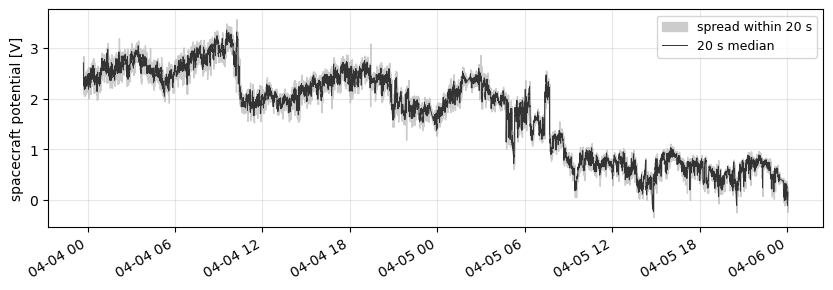

In [3]:
from build_scpot_table_from_soar_l3 import buildTable, discoverDailyFiles

SCPOT_TABLE = CALIBRATION_DIR / 'scpot_rpw_l3_20230404_20230405_20s.csv'
SCPOT_CDF_DIR = RAW_DIR / 'rpw_l3_scpot'
startDay, endDay = pd.Timestamp('2023-04-04'), pd.Timestamp('2023-04-05')
if discoverDailyFiles(startDay, endDay, str(SCPOT_CDF_DIR)):
    scpotTable = buildTable(startDay, endDay, str(SCPOT_CDF_DIR), binSeconds=20, minQualityFlag=3, marginMinutes=30)
    print('rebuilt from the daily CDFs; identical to the shipped table:',
          np.allclose(scpotTable['scpotV'].to_numpy(), pd.read_csv(SCPOT_TABLE)['scpotV'].to_numpy(), atol=5e-5))
else:
    scpotTable = pd.read_csv(SCPOT_TABLE, parse_dates=['time'])
    print('daily CDFs not on disk; using the shipped table')

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(scpotTable['time'], scpotTable['scpotV'] - scpotTable['scpotSigmaV'], scpotTable['scpotV'] + scpotTable['scpotSigmaV'], color='0.8', label='spread within 20 s')
ax.plot(scpotTable['time'], scpotTable['scpotV'], color='0.2', linewidth=0.7, label='20 s median')
ax.set_ylabel('spacecraft potential [V]'); ax.grid(alpha=0.3); ax.legend(fontsize=9); fig.autofmt_xdate()
print(f"{len(scpotTable)} rows, {scpotTable['time'].iloc[0]} .. {scpotTable['time'].iloc[-1]}, median {scpotTable['scpotV'].median():.2f} V")

## 3. Run the preprocessing

`preprocess_main` takes the file lists, or a time range with `psd_source='soar'`
(download) or `'local'` (files on disk), plus the potential table and the output
directory. `compute_break_energy` would chain the break-energy step; it is off here so
that section 5 can show it separately.

In [4]:
import time
from preprocess_data_for_fit_hdf5 import preprocess_main

PROCESSED_DIR = REPO_ROOT / 'data' / 'processed' / 'demo_2023-04-04'
if hasRawFiles:
    startTime = time.time()
    processedPaths = preprocess_main(
        eas1_files=eas1PsdFiles, eas2_files=eas2PsdFiles,
        count_eas1_files=eas1CountFiles, count_eas2_files=eas2CountFiles,
        download_dir=str(RAW_DIR), output_dir=str(PROCESSED_DIR),
        shift_SCPOT=True, scpot_file=str(SCPOT_TABLE),
        time_resolution='1min', compute_break_energy=False, psd_source='local',
    )
    print(f'\nfinished in {(time.time() - startTime) / 60:.1f} min ->', processedPaths)

Logging this run to /disk/plasma/xw2/SO-EAS-eVDF_Fitting/data/processed/demo_2023-04-04/preprocess_20260917_101509.log
Using provided EAS1 and EAS2 data files list.

Processing EAS files...


ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS1_ENERGY, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS1_ENERGY_delta_upper, but the

ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable EAS1_TO_SRF, but the dimensions do not match.
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/cdflib/xarray/cdf_to_xarray.py:619: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  created_vars[var_name] = xr.Variable(var_dims, var_data, attrs=var_atts)  # type: ignore[no-untyped-call]


ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS2_ENERGY, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS2_ENERGY_delta_upper, but the

ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable EAS2_TO_SRF, but the dimensions do not match.
/disk/anaconda/xw2/miniconda3/envs/SunSolarWind/lib/python3.10/site-packages/cdflib/xarray/cdf_to_xarray.py:619: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  created_vars[var_name] = xr.Variable(var_dims, var_data, attrs=var_atts)  # type: ignore[no-untyped-call]


...

ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS1_ENERGY, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS1_ENERGY_delta_upper, but the

Reading EAS2 count data...


ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_ELEVATION_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_upper, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS_AZIMUTH_delta_lower, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS2_ENERGY, but the dimensions do not match.
ISTP Compliance Warning: EPOCH is listed as the DEPEND_0 for variable SWA_EAS2_ENERGY_delta_upper, but the

/disk/plasma/xw2/SO-EAS-eVDF_Fitting/src/preprocess_data_for_fit_hdf5.py:1167: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 values to the DataArray or Variable constructor; it can be silenced by converting the values to nanosecond precision ahead of time.
  countEAS1['EPOCH'] = countEAS1['EPOCH'].astype('datetime64[s]')
/disk/plasma/xw2/SO-EAS-eVDF_Fitting/src/preprocess_data_for_fit_hdf5.py:1168: UserWarning: Converting non-nanosecond precision datetime values to nanosecond precision. This behavior can eventually be relaxed in xarray, as it is an artifact from pandas which is now beginning to support non-nanosecond precision values. This warning is caused by passing non-nanosecond np.datetime64 or np.timedelta64 


Identifying valid time regions...
Found 2160 common time points across all datasets
Time range: 2023-04-04 00:00:08 to 2023-04-04 05:59:58
Creating time intervals...
Created 1 time intervals
Interval 1: 2023-04-04 00:00:08 to 2023-04-04 05:59:58 (duration: 0 days 05:59:50)

Processing interval 1/1: 2023-04-04 00:00:08 to 2023-04-04 05:59:58
Interval 1/1 already processed (VDF_eas_forFitting_20230404000008_20230404055958_1min.h5), skip.

## 4. What the file contains

One time-indexed dataset per quantity:

- `pa_vec_in`: the pixel grid the fit works on (pitch angle, PSD, $v_\parallel$,
  $v_\perp$, counts per pixel);
- `pad_in`: the pitch-angle distribution;
- `n_saturated_pixels`: the saturation census of step 2;
- the rest: ancillary measurements per epoch.

The attributes record where the potential came from and what was masked.

In [5]:
import h5py

if hasRawFiles:
    processedFile = sorted(PROCESSED_DIR.glob('VDF_eas_forFitting_*.h5'))[0]
    with h5py.File(processedFile, 'r') as h5:
        def describe(name, item):
            if isinstance(item, h5py.Dataset):
                print(f'{name:28s} {str(item.shape):22s} {item.dtype}')
        h5.visititems(describe)
        times = pd.to_datetime(h5['time_EAS'][()])
        saturated = h5['n_saturated_pixels'][()]
        print('\nattributes:', dict(h5.attrs))
    print(f'\n{processedFile.name}: {len(times)} epochs, {times[0]} to {times[-1]}, '
          f'{processedFile.stat().st_size / 1e6:.0f} MB on disk')
    print(f'epochs with masked saturation blocks: {int((saturated > 0).sum())} '
          f'(pixels: {int(saturated.sum())})')

## 5. Break energies for the new file

The crossing method (notebook 03) runs on the whole directory and writes
`<stem>_two_population_crossing.csv` next to the data, where the fitting runner looks
for it (`--break-dir` to point elsewhere).

In [6]:
from compute_break_energy_crossing import runCrossingPipeline

if hasRawFiles:
    runCrossingPipeline(PROCESSED_DIR, PROCESSED_DIR, workers=4, writeCombined=False, overwrite=True)
    breakTable = pd.read_csv(PROCESSED_DIR / (processedFile.stem + '_two_population_crossing.csv'))
    print(breakTable['status'].value_counts().to_dict())
    print(breakTable[['epoch_id', 'timestamp', 'scpot_V', 'break_E_eV', 'core_T_eV', 'status']].iloc[68:73].round(2).to_string(index=False))

## 6. Fit one epoch and compare with the bundled example

The bundled subset is epochs 50-79 of this segment, so the fit of the
demonstration epoch (01:10:08 UT, epoch 20 of the subset, epoch 70 of the segment)
must reproduce the reference values exactly. The archives occasionally reprocess MAG,
PAS or RPW; if they have, the ratios move away from 1 by the corresponding amount.

In [7]:
from evdf_poisson import fitOneEpoch

if hasRawFiles:
    reference = pd.read_csv(RESULTS_DIR / 'summary.csv')
    referenceRow = reference[reference['time_iso'] == '2023-04-04 01:10:08'].iloc[0]
    newEpoch = int(np.flatnonzero(times == pd.Timestamp('2023-04-04 01:10:08'))[0])
    newBreak = float(breakTable.loc[newEpoch, 'break_E_eV'])
    newRow = fitOneEpoch(processedFile, newEpoch, breakEnergyEv=newBreak)
    columns = ['n_c', 'T_par_c_eV', 'T_perp_c_eV', 'n_h', 'T_par_h_eV', 'kappa_h', 'n_b', 'T_par_b_eV', 'deviance_per_dof', 'break_energy_eV']
    comparison = pd.DataFrame({'bundled example': referenceRow[columns],
                               'new preprocessing': pd.Series(newRow)[columns]}).astype(float)
    comparison['ratio'] = comparison['new preprocessing'] / comparison['bundled example']
    display(comparison.round(6))

,bundled example,new preprocessing,ratio
n_c,9.377649,9.377649,1.0
T_par_c_eV,16.814685,16.814685,1.0
T_perp_c_eV,15.412832,15.412832,1.0
n_h,0.185209,0.185209,1.0
T_par_h_eV,68.416604,68.416604,1.0
kappa_h,5.071218,5.071218,1.0
n_b,0.134694,0.134694,1.0
T_par_b_eV,32.762614,32.762614,1.0
deviance_per_dof,0.609446,0.609446,1.0
break_energy_eV,139.034105,139.034105,1.0


## 7. Your own interval

Three commands, from the repository root with `PYTHONPATH=src`:

1. preprocess:
   `preprocess_main(start_time, end_time, psd_source='soar', shift_SCPOT=True, scpot_file=..., output_dir=D)`,
   or edit the `__main__` block of `src/preprocess_data_for_fit_hdf5.py`. Leave
   `scpot_file` out for intervals before 2023;
2. `python src/compute_break_energy_crossing.py --vdf-dir D --output-dir D`;
3. `python -m evdf_poisson.runner --data-dir D --out results/fitting/<name> --workers N`.

Practical notes:

- keep a segment within one SOAR file version and within MAG coverage (epochs without
  MAG are dropped);
- six hours at 1-minute cadence: ~650 MB of RAM, a ~600 MB file, ~360 epochs; a day is
  four files;
- fitting takes ~6 s per epoch and core: a day is about 40 minutes on 4 workers,
  5 minutes on 32.